# 06 Style map

Eligible fighters on the 4 varimax-rotated style axes (`notebooks/05_style_axes.ipynb`, `src/style_axes.py`), built from era-relative,
within-division style features. Axes are unnamed. Each axis label lists the features that load on it (|loading| ≥ 0.4), with signs.
Scores are in SD units.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src"))
import features as F
import style_axes as A

plt.rcParams.update({"figure.dpi": 80, "axes.spines.top": False, "axes.spines.right": False, "font.size": 9})
profiles = F.build_profiles(None)
axes = A.StyleAxes.load(A.MODEL_DIR / f"style_axes_m{A.CHOSEN_AXES}.joblib")
S = axes.transform(profiles).set_index("fighter_name")
L = axes.loadings
def label(a):
    parts = [f"{'+' if v > 0 else '−'}{f}" for f, v in L[a].sort_values(key=abs, ascending=False).items() if abs(v) >= 0.4]
    return f"{a.replace('_', ' ')}  ({', '.join(parts)})"
LABEL = ["Georges St-Pierre", "Khabib Nurmagomedov", "Jon Jones", "Anderson Silva", "Conor McGregor", "Israel Adesanya",
         "Max Holloway", "Demian Maia", "Charles Oliveira", "Merab Dvalishvili", "Jose Aldo", "Francis Ngannou",
         "Amanda Nunes", "Valentina Shevchenko", "Zhang Weili", "Joanna Jedrzejczyk", "Alexander Volkanovski", "Kamaru Usman",
         "Nate Diaz", "Jailton Almeida", "Sean Strickland", "Demetrious Johnson"]
LABEL = [n for n in LABEL if n in S.index]
print(f"{len(S):,} fighters; labelled {len(LABEL)}")

def style_map(xa, ya, offsets=None, title=""):
    offsets = offsets or {}
    fig, ax = plt.subplots(figsize=(11, 8.5))
    ax.scatter(S[xa], S[ya], s=8, color="#bbbbbb", alpha=0.7, lw=0)
    for n in LABEL:
        x, y = S.loc[n, xa], S.loc[n, ya]
        ax.scatter([x], [y], s=30, color="#4C72B0", zorder=3)
        ax.annotate(n, (x, y), xytext=offsets.get(n, (5, 3)), textcoords="offset points", fontsize=8.5, zorder=4)
    ax.axhline(0, color="k", lw=0.5); ax.axvline(0, color="k", lw=0.5)
    ax.set_xlabel(label(xa)); ax.set_ylabel(label(ya)); ax.set_title(title)
    plt.show()

1,240 fighters; labelled 22


## Axis 1 vs axis 2

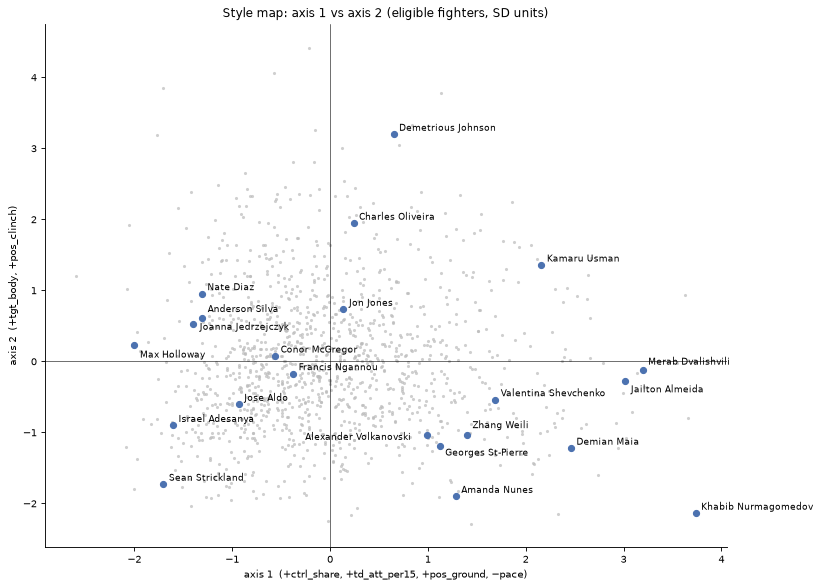

,axis_1,axis_2,axis_3,axis_4
fighter_name,,,,
Max Holloway,-2.00,0.23,-1.40,-1.15
Sean Strickland,-1.70,-1.73,-1.89,-2.26
Israel Adesanya,-1.60,-0.90,-0.61,2.38
Joanna Jedrzejczyk,-1.40,0.52,-1.83,1.73
Nate Diaz,-1.31,0.96,0.68,-1.87
Anderson Silva,-1.31,0.62,0.09,2.29
Jose Aldo,-0.93,-0.60,-0.56,-0.08
Conor McGregor,-0.56,0.08,-0.83,-0.24
Francis Ngannou,-0.38,-0.17,0.71,-0.25


In [2]:
OFF12 = {"Joanna Jedrzejczyk": (6, -5), "Max Holloway": (5, -11), "Anderson Silva": (5, 5), "Zhang Weili": (5, 6), "Alexander Volkanovski": (-110, -4), "Georges St-Pierre": (5, -9), "Jailton Almeida": (5, -10), "Merab Dvalishvili": (5, 5)}
style_map("axis_1", "axis_2", OFF12, title="Style map: axis 1 vs axis 2 (eligible fighters, SD units)")
display(S.loc[LABEL, axes.axis_names].round(2).sort_values("axis_1"))

## Axis 3 vs axis 4

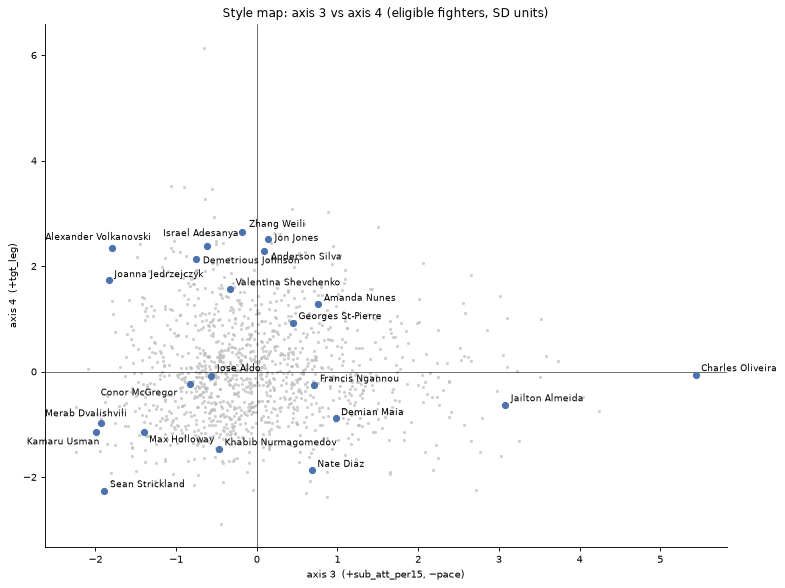

In [3]:
OFF34 = {"Zhang Weili": (6, 5), "Israel Adesanya": (-40, 9), "Jon Jones": (6, -2), "Anderson Silva": (6, -8), "Demetrious Johnson": (6, -4), "Alexander Volkanovski": (-60, 7), "Kamaru Usman": (-62, -11), "Max Holloway": (5, -9), "Merab Dvalishvili": (-50, 6), "Jose Aldo": (5, 4), "Conor McGregor": (-80, -10)}
style_map("axis_3", "axis_4", OFF34, title="Style map: axis 3 vs axis 4 (eligible fighters, SD units)")

## All pairs

Every pair of axes, unlabelled, to show the overall shape of the style space. The axes are uncorrelated by construction.

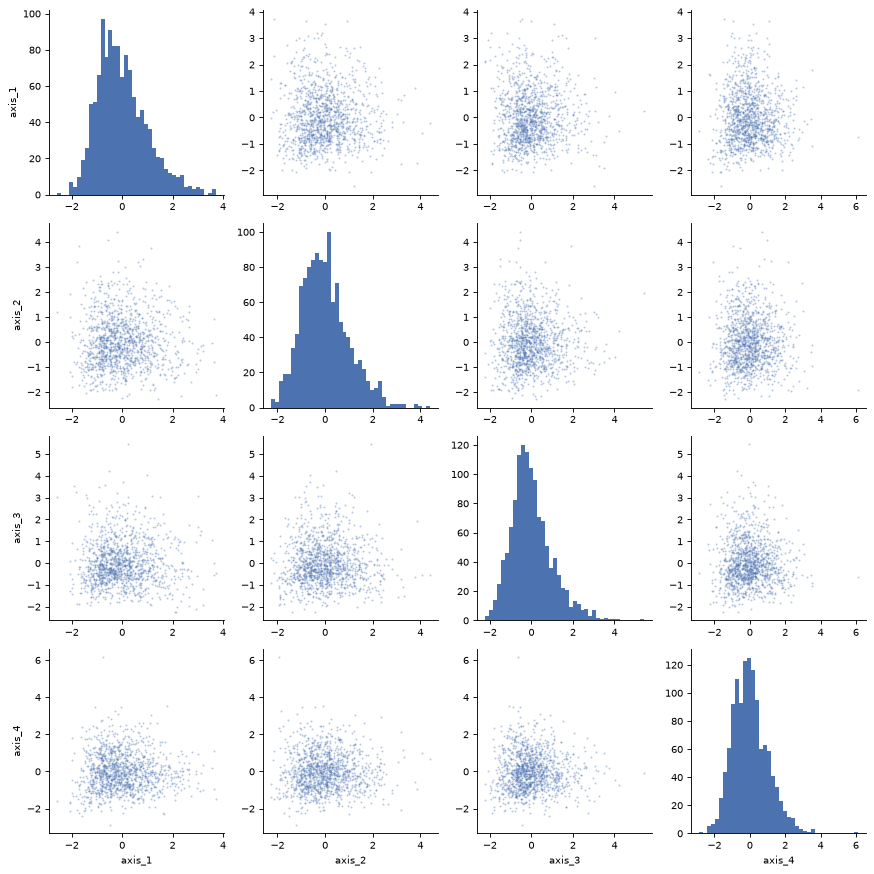

In [4]:
names = axes.axis_names
fig, grid = plt.subplots(len(names), len(names), figsize=(11, 11))
for i, yi in enumerate(names):
    for j, xj in enumerate(names):
        a = grid[i, j]
        if i == j:
            a.hist(S[xj], bins=40, color="#4C72B0")
        else:
            a.scatter(S[xj], S[yi], s=3, alpha=0.4, lw=0, color="#4C72B0")
        if i == len(names) - 1: a.set_xlabel(xj)
        if j == 0: a.set_ylabel(yi)
plt.tight_layout(); plt.show()